# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The EV Battery Health Dataset](https://www.kaggle.com/datasets/jayangupta00/ev-battery-degradation-and-telemetry)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

/kaggle/input/datasets/jayangupta00/ev-battery-degradation-and-telemetry/ev_battery_health_telemetry.csv


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('ev_battery_health_telemetry.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,vehicle_id,battery_chemistry,nominal_capacity_kwh,state_of_health_pct,odometer_reading_km,equivalent_full_cycles,fast_charging_ratio,avg_ambient_temp_c,internal_resistance_mohm,annual_degradation_rate_pct,warranty_status
0,EV-BAT-10000,NMC,75.0,96.22,44438.0,114.8,0.481,17.5,13.24,1.39,In-Warranty
1,EV-BAT-10001,NMC,100.0,94.99,183975.0,325.8,0.171,10.6,13.49,0.52,Out-of-Warranty
2,EV-BAT-10002,NMC,100.0,94.62,214357.0,386.0,0.227,23.8,14.84,0.48,Out-of-Warranty
3,EV-BAT-10003,NMC,82.0,93.02,209010.0,454.4,0.321,22.9,14.53,0.64,Out-of-Warranty
4,EV-BAT-10004,NMC,82.0,97.53,49707.0,103.3,0.562,16.7,13.71,0.83,In-Warranty


## last Five row

In [4]:
df.tail()

,vehicle_id,battery_chemistry,nominal_capacity_kwh,state_of_health_pct,odometer_reading_km,equivalent_full_cycles,fast_charging_ratio,avg_ambient_temp_c,internal_resistance_mohm,annual_degradation_rate_pct,warranty_status
4495,EV-BAT-14495,NMC,95.0,92.21,160871.0,306.4,0.336,28.8,15.33,0.91,Out-of-Warranty
4496,EV-BAT-14496,NMC,95.0,98.50,57472.0,98.6,0.079,23.2,12.28,0.44,In-Warranty
4497,EV-BAT-14497,NCA,90.0,94.69,109161.0,213.5,0.252,16.7,14.11,0.89,In-Warranty
4498,EV-BAT-14498,NMC,100.0,96.19,208195.0,385.4,0.296,28.1,13.72,0.35,Out-of-Warranty
4499,EV-BAT-14499,LFP,60.0,93.32,178227.0,537.3,0.445,28.6,14.76,0.71,Out-of-Warranty


## Shape of our dataset

In [5]:
df.shape

(4500, 11)

## List out all columns

In [6]:
df.columns

Index(['vehicle_id', 'battery_chemistry', 'nominal_capacity_kwh',
       'state_of_health_pct', 'odometer_reading_km', 'equivalent_full_cycles',
       'fast_charging_ratio', 'avg_ambient_temp_c', 'internal_resistance_mohm',
       'annual_degradation_rate_pct', 'warranty_status'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

vehicle_id                      object
battery_chemistry               object
nominal_capacity_kwh           float64
state_of_health_pct            float64
odometer_reading_km            float64
equivalent_full_cycles         float64
fast_charging_ratio            float64
avg_ambient_temp_c             float64
internal_resistance_mohm       float64
annual_degradation_rate_pct    float64
warranty_status                 object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   vehicle_id                   4500 non-null   object 
 1   battery_chemistry            4500 non-null   object 
 2   nominal_capacity_kwh         4500 non-null   float64
 3   state_of_health_pct          4500 non-null   float64
 4   odometer_reading_km          4500 non-null   float64
 5   equivalent_full_cycles       4500 non-null   float64
 6   fast_charging_ratio          4500 non-null   float64
 7   avg_ambient_temp_c           4500 non-null   float64
 8   internal_resistance_mohm     4500 non-null   float64
 9   annual_degradation_rate_pct  4500 non-null   float64
 10  warranty_status              4500 non-null   object 
dtypes: float64(8), object(3)
memory usage: 386.8+ KB


## Check Null Value

In [9]:
df.isnull().sum()

vehicle_id                     0
battery_chemistry              0
nominal_capacity_kwh           0
state_of_health_pct            0
odometer_reading_km            0
equivalent_full_cycles         0
fast_charging_ratio            0
avg_ambient_temp_c             0
internal_resistance_mohm       0
annual_degradation_rate_pct    0
warranty_status                0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,nominal_capacity_kwh,state_of_health_pct,odometer_reading_km,equivalent_full_cycles,fast_charging_ratio,avg_ambient_temp_c,internal_resistance_mohm,annual_degradation_rate_pct
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000
mean,77.699333,95.427058,112643.888222,275.691778,0.287081,24.093689,14.060280,0.975338
std,15.828110,2.323031,62027.040718,166.984999,0.160011,7.154070,1.165002,0.862484
min,55.000000,84.860000,5043.000000,20.000000,0.003000,-1.100000,11.200000,0.150000
25%,62.000000,93.980000,59633.250000,140.150000,0.159750,19.200000,13.220000,0.520000
50%,82.000000,95.750000,112778.500000,263.500000,0.269000,24.000000,13.940000,0.720000
75%,95.000000,97.230000,166369.250000,388.750000,0.393000,28.900000,14.770000,1.100000
max,100.000000,98.500000,219884.000000,745.200000,0.903000,47.400000,19.640000,12.710000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

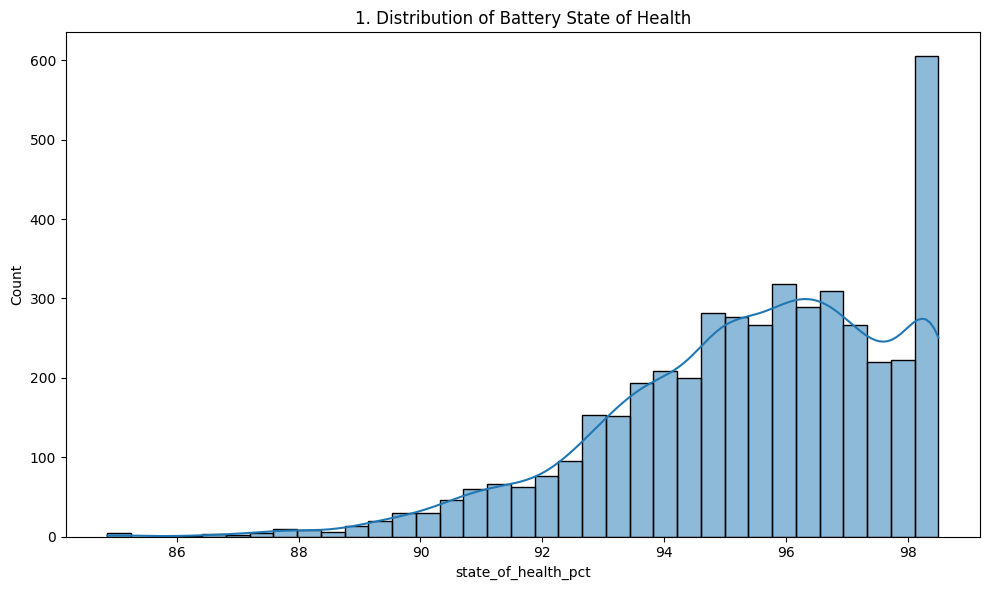

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='state_of_health_pct', kde=True)
plt.title(f'{plot_no}. Distribution of Battery State of Health')
show_fig()
plot_no += 1

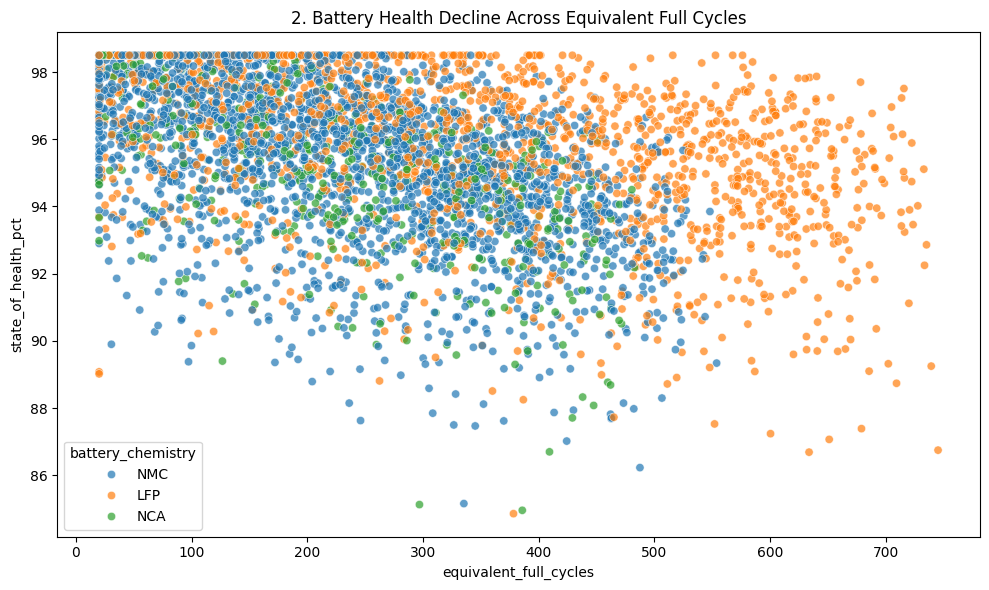

In [14]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='equivalent_full_cycles', y='state_of_health_pct', hue='battery_chemistry', alpha=0.7)
plt.title(f'{plot_no}. Battery Health Decline Across Equivalent Full Cycles')
show_fig()
plot_no += 1

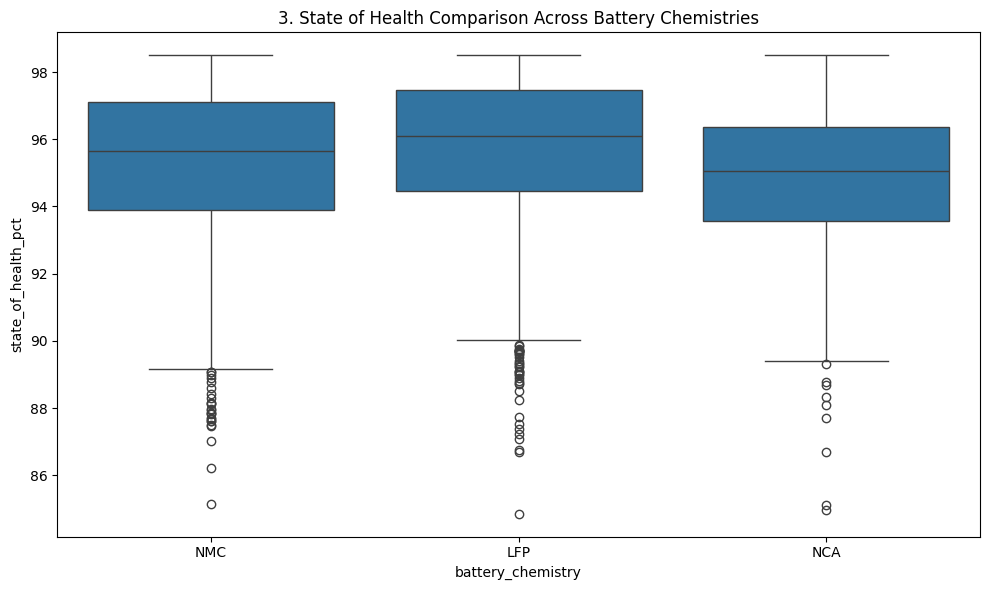

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='battery_chemistry', y='state_of_health_pct')
plt.title(f'{plot_no}. State of Health Comparison Across Battery Chemistries')
show_fig()
plot_no += 1

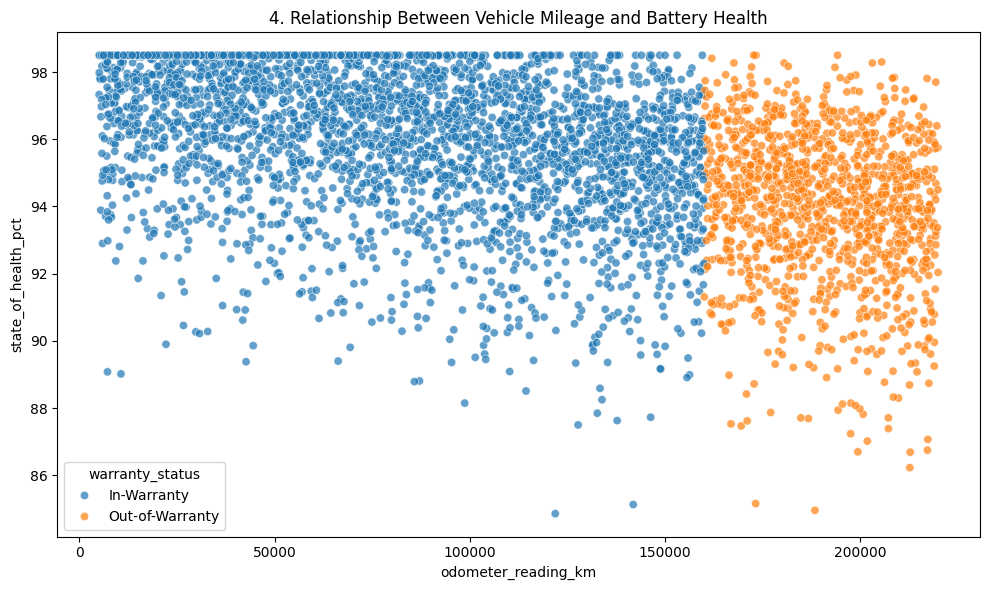

In [16]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='odometer_reading_km', y='state_of_health_pct', hue='warranty_status', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Vehicle Mileage and Battery Health')
show_fig()
plot_no += 1

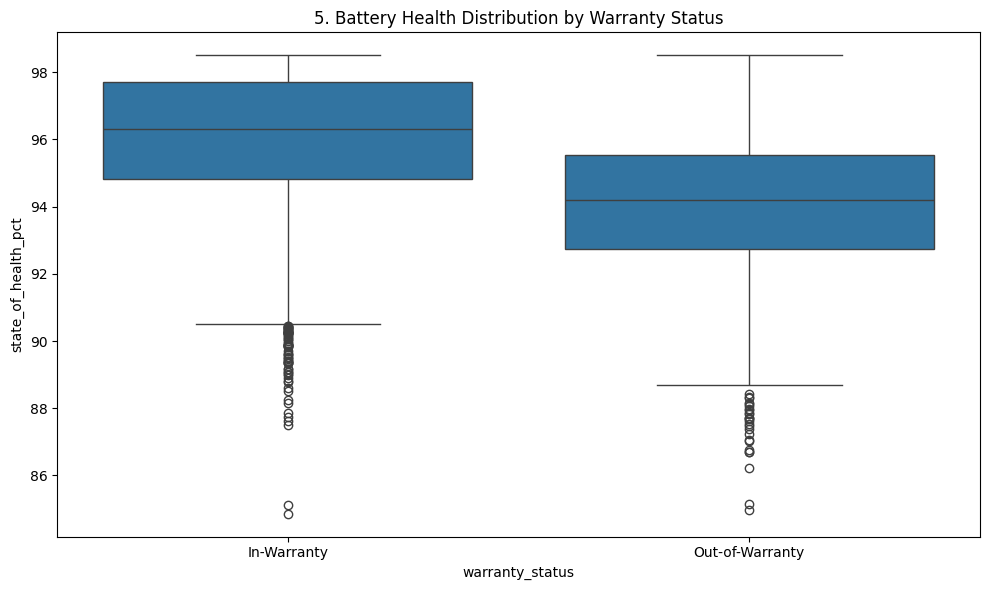

In [17]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='warranty_status', y='state_of_health_pct')
plt.title(f'{plot_no}. Battery Health Distribution by Warranty Status')
show_fig()
plot_no += 1

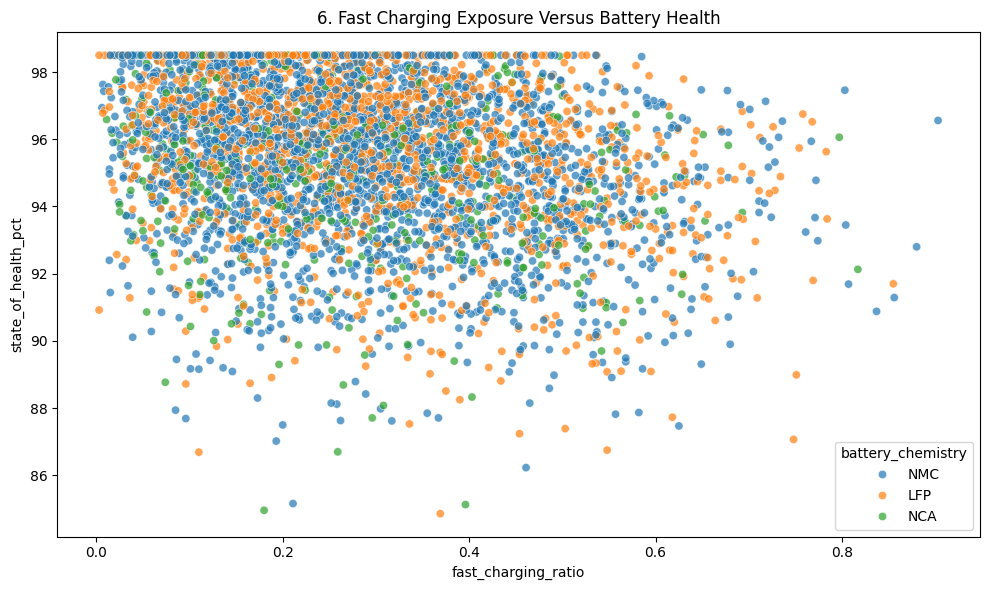

In [18]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='fast_charging_ratio', y='state_of_health_pct', hue='battery_chemistry', alpha=0.7)
plt.title(f'{plot_no}. Fast Charging Exposure Versus Battery Health')
show_fig()
plot_no += 1

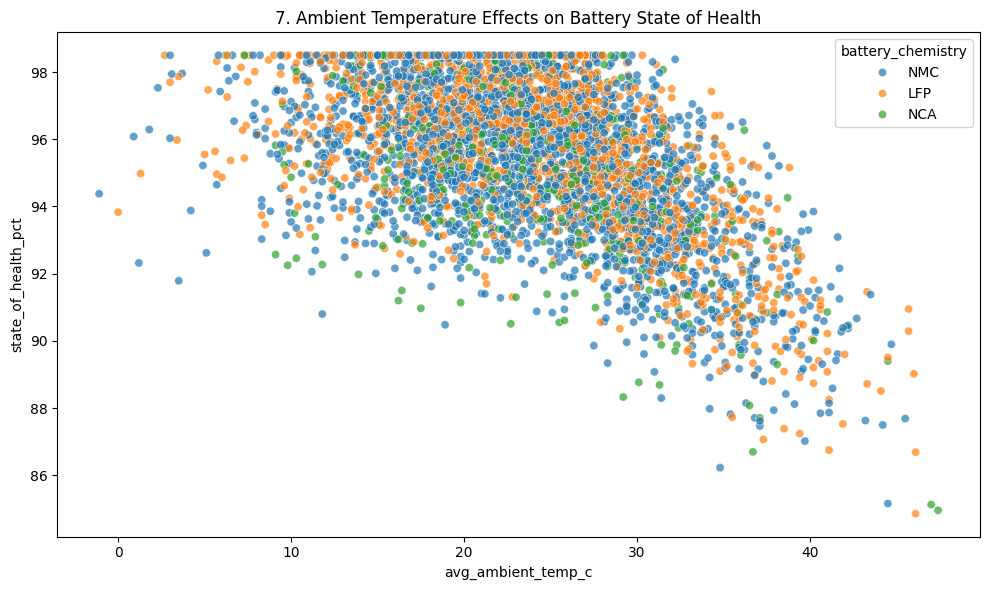

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='avg_ambient_temp_c', y='state_of_health_pct', hue='battery_chemistry', alpha=0.7)
plt.title(f'{plot_no}. Ambient Temperature Effects on Battery State of Health')
show_fig()
plot_no += 1

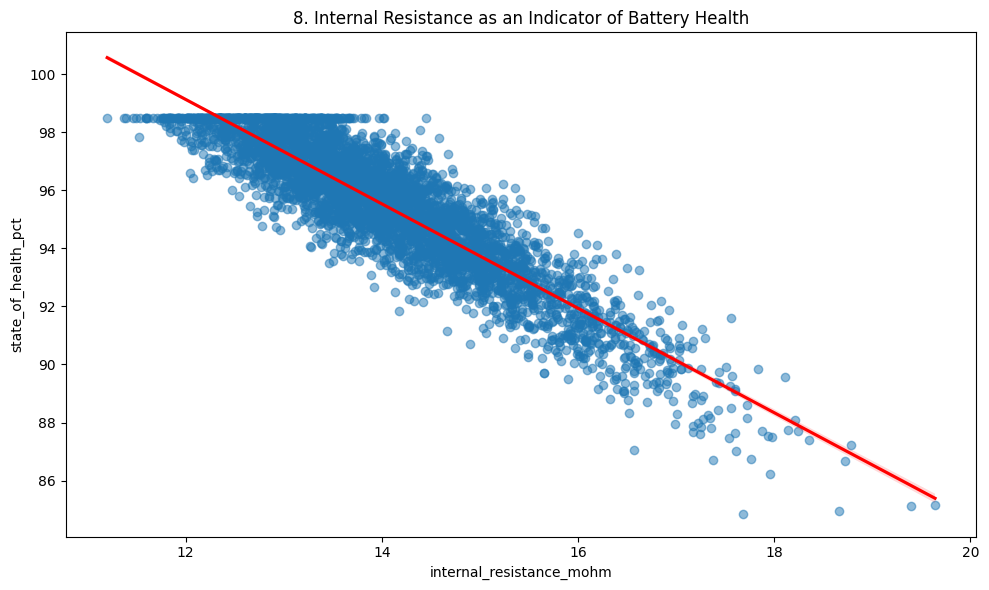

In [20]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='internal_resistance_mohm', y='state_of_health_pct', scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Internal Resistance as an Indicator of Battery Health')
show_fig()
plot_no += 1

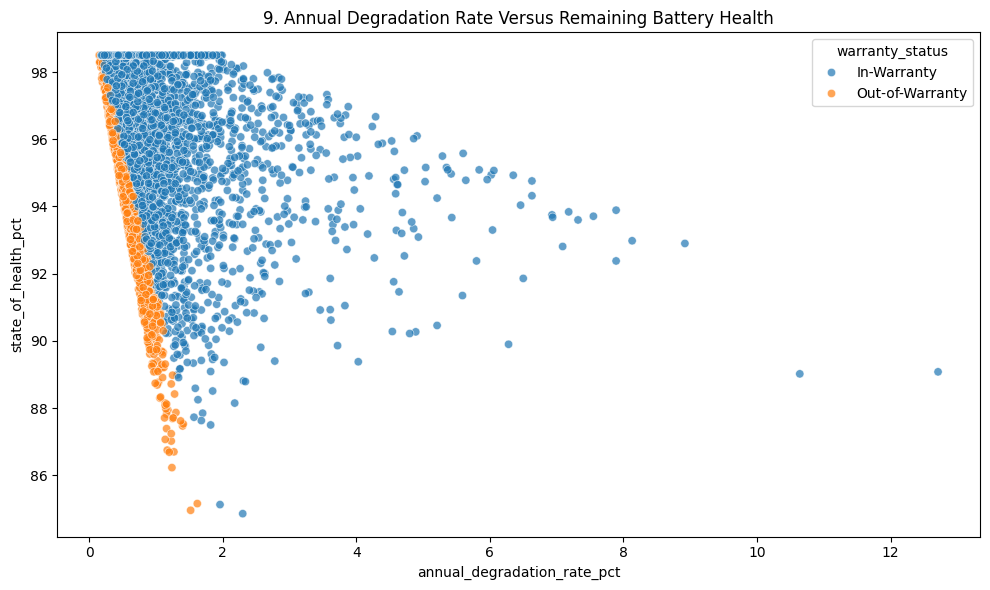

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='annual_degradation_rate_pct', y='state_of_health_pct', hue='warranty_status', alpha=0.7)
plt.title(f'{plot_no}. Annual Degradation Rate Versus Remaining Battery Health')
show_fig()
plot_no += 1

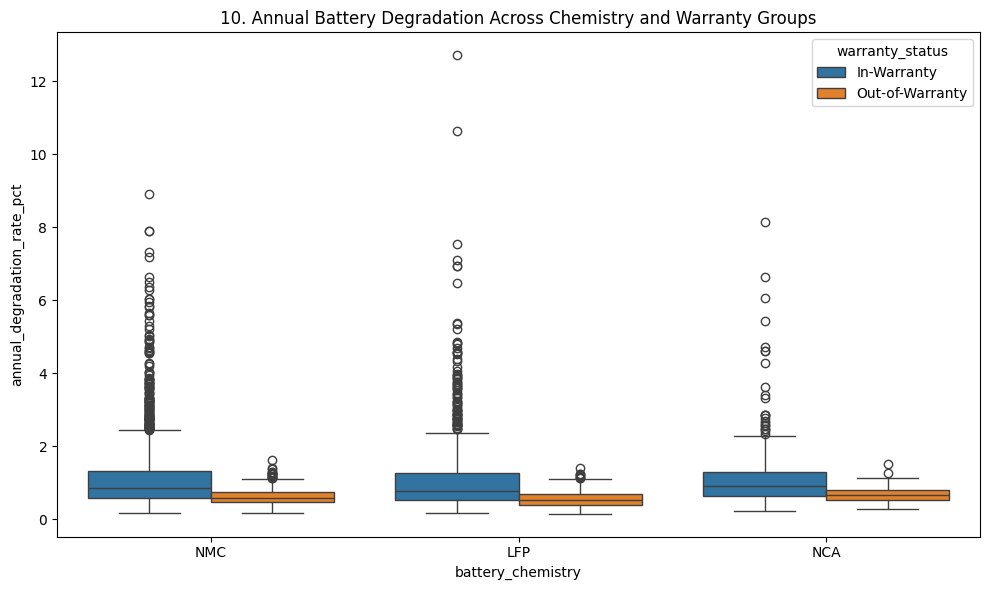

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='battery_chemistry', y='annual_degradation_rate_pct', hue='warranty_status')
plt.title(f'{plot_no}. Annual Battery Degradation Across Chemistry and Warranty Groups')
show_fig()
plot_no += 1

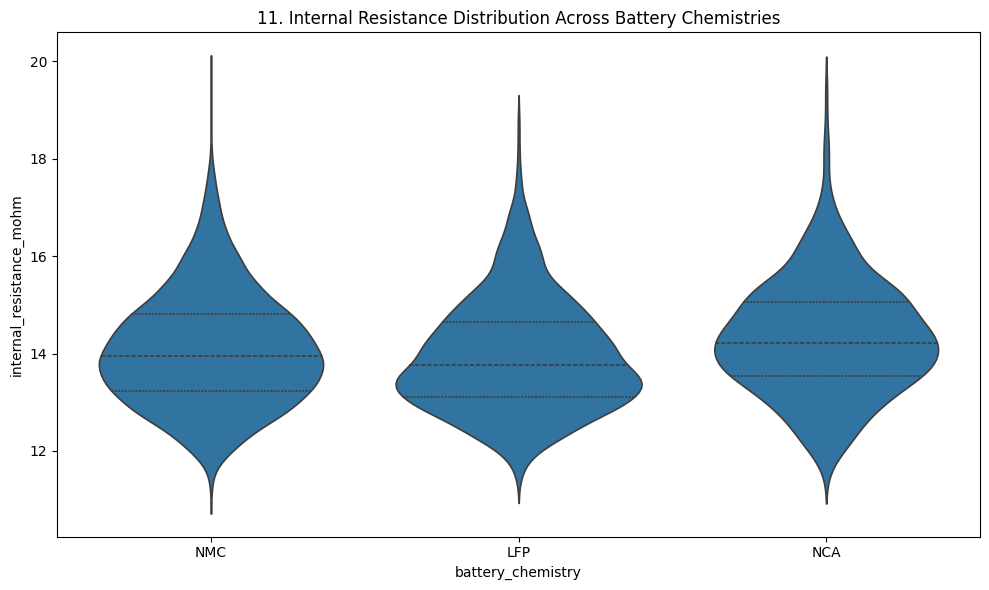

In [23]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='battery_chemistry', y='internal_resistance_mohm', inner='quartile')
plt.title(f'{plot_no}. Internal Resistance Distribution Across Battery Chemistries')
show_fig()
plot_no += 1

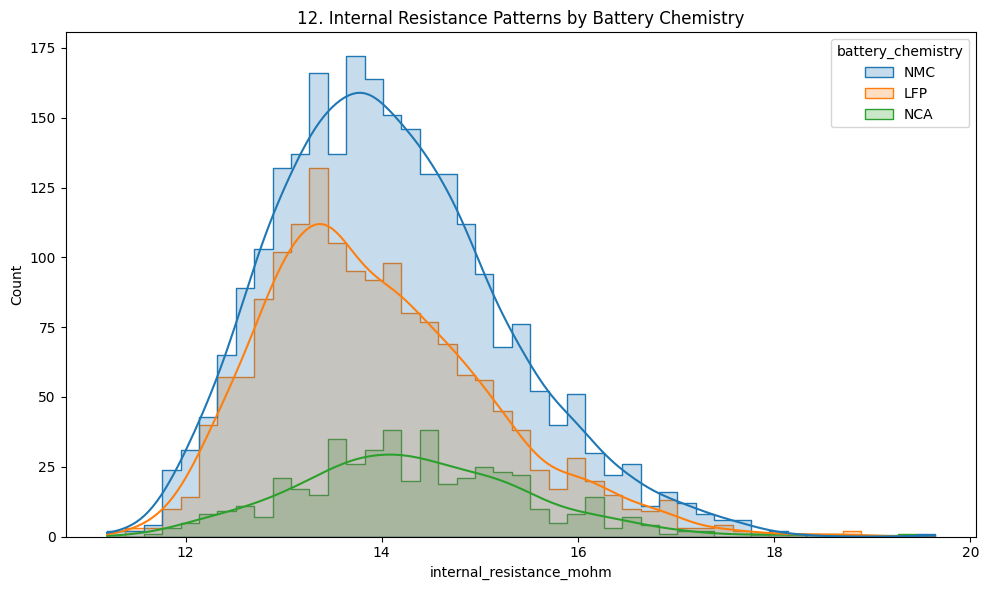

In [24]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='internal_resistance_mohm', hue='battery_chemistry', kde=True, element='step')
plt.title(f'{plot_no}. Internal Resistance Patterns by Battery Chemistry')
show_fig()
plot_no += 1

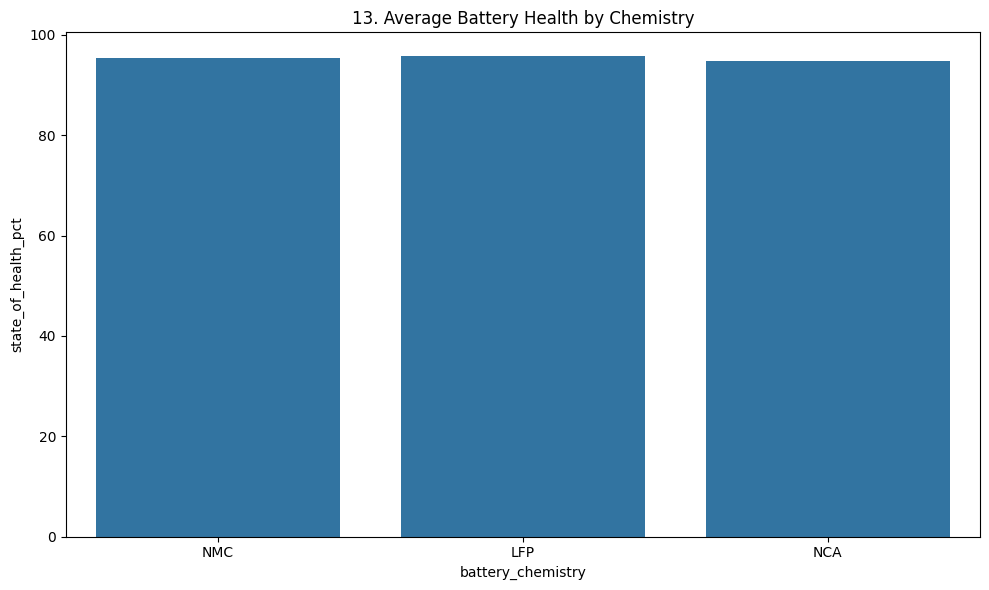

In [25]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='battery_chemistry', y='state_of_health_pct', errorbar=None)
plt.title(f'{plot_no}. Average Battery Health by Chemistry')
show_fig()
plot_no += 1

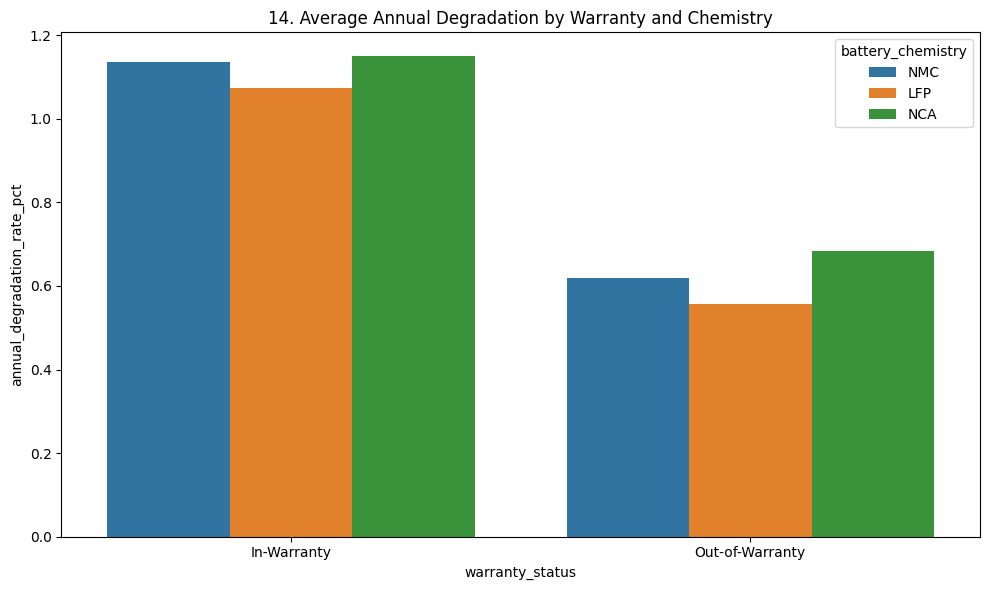

In [26]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='warranty_status', y='annual_degradation_rate_pct', hue='battery_chemistry', errorbar=None)
plt.title(f'{plot_no}. Average Annual Degradation by Warranty and Chemistry')
show_fig()
plot_no += 1

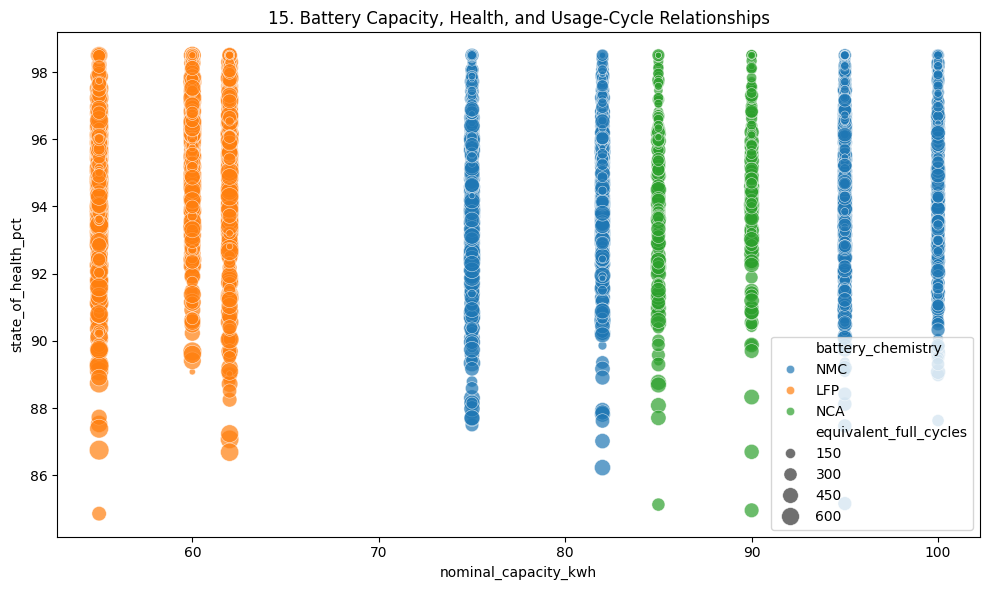

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='nominal_capacity_kwh', y='state_of_health_pct', hue='battery_chemistry', size='equivalent_full_cycles', sizes=(20,200), alpha=0.7)
plt.title(f'{plot_no}. Battery Capacity, Health, and Usage-Cycle Relationships')
show_fig()
plot_no += 1

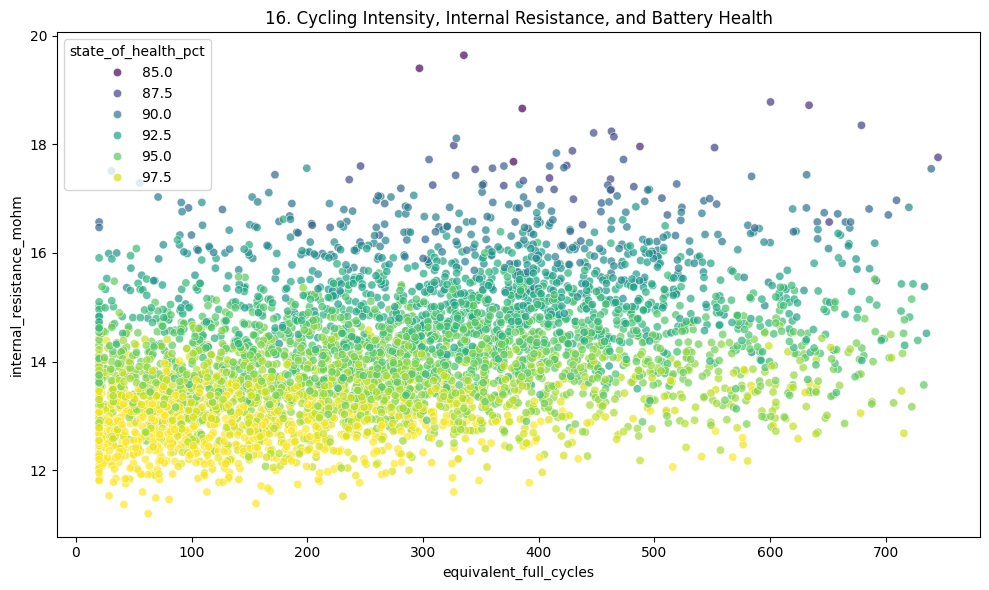

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='equivalent_full_cycles', y='internal_resistance_mohm', hue='state_of_health_pct', palette='viridis', alpha=0.7)
plt.title(f'{plot_no}. Cycling Intensity, Internal Resistance, and Battery Health')
show_fig()
plot_no += 1

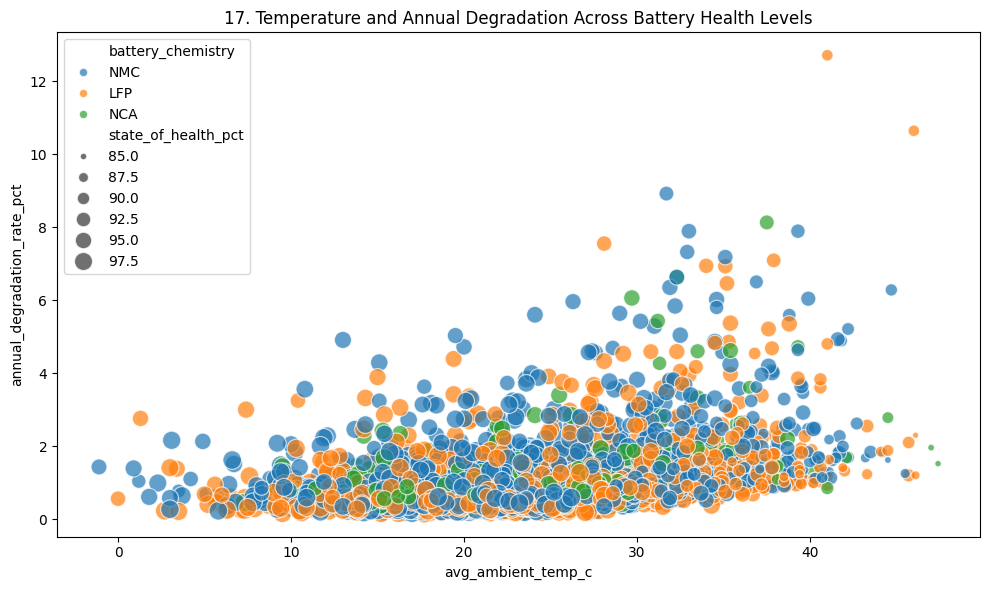

In [29]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='avg_ambient_temp_c', y='annual_degradation_rate_pct', hue='battery_chemistry', size='state_of_health_pct', sizes=(20,180), alpha=0.7)
plt.title(f'{plot_no}. Temperature and Annual Degradation Across Battery Health Levels')
show_fig()
plot_no += 1

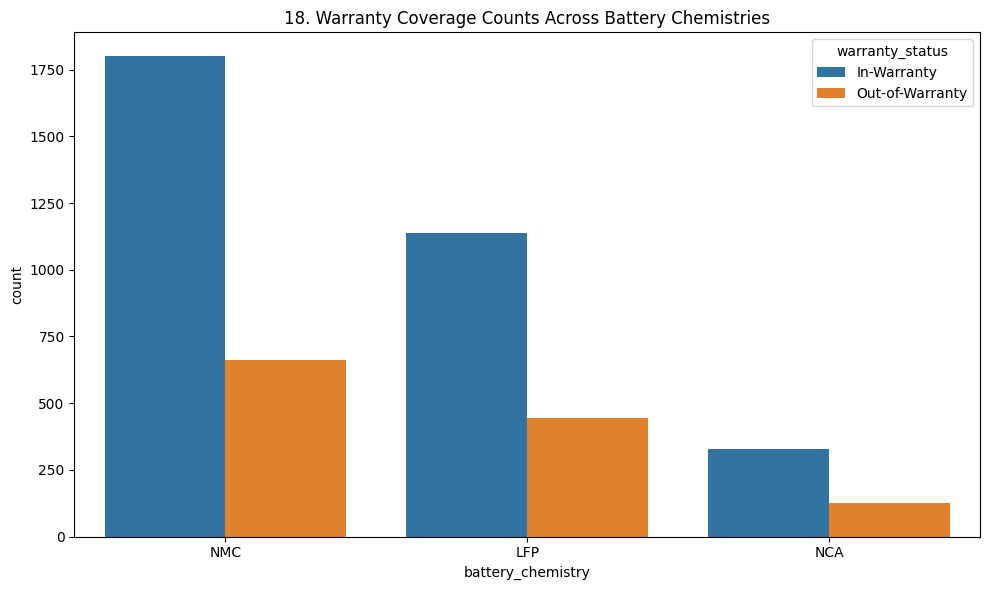

In [30]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='battery_chemistry', hue='warranty_status')
plt.title(f'{plot_no}. Warranty Coverage Counts Across Battery Chemistries')
show_fig()
plot_no += 1

<Figure size 1000x600 with 0 Axes>

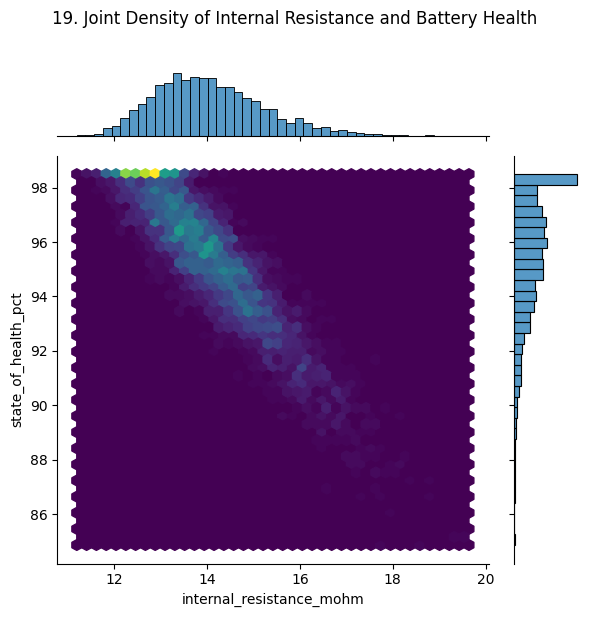

In [31]:
fig = plt.figure(figsize=(10,6))
sns.jointplot(data=df, x='internal_resistance_mohm', y='state_of_health_pct', kind='hex', height=6, cmap='viridis')
plt.suptitle(f'{plot_no}. Joint Density of Internal Resistance and Battery Health', y=1.02)
show_fig()
plot_no += 1

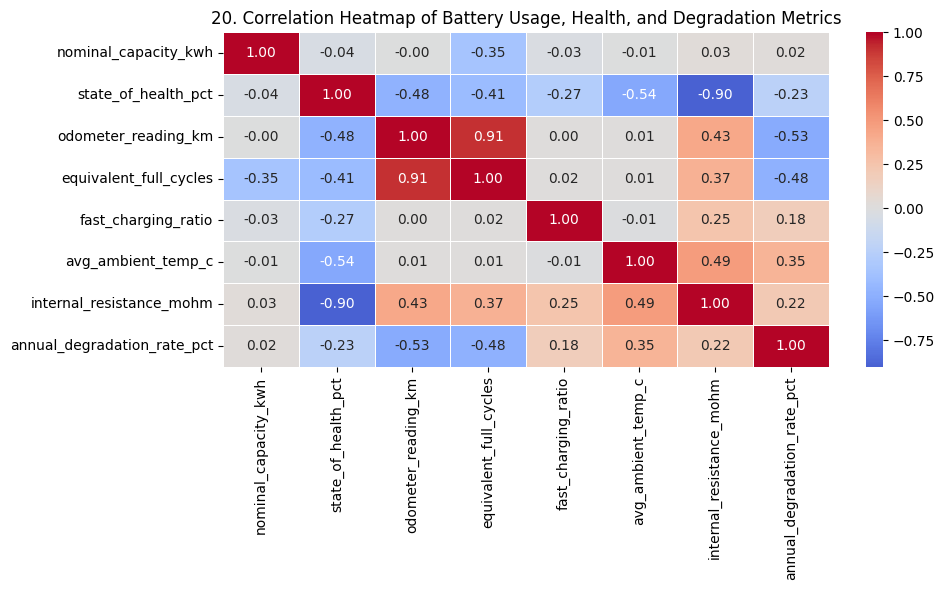

In [32]:
corr = df.select_dtypes(include='number').drop(columns=['vehicle_id'], errors='ignore').corr()

fig = plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0)
plt.title(f'{plot_no}. Correlation Heatmap of Battery Usage, Health, and Degradation Metrics')
show_fig()
plot_no += 1

# Model Training

## Prepare features and target

In [33]:
target = 'state_of_health_pct'
data = df.dropna(subset=[target]).copy()
X = data.drop(columns=[target, 'vehicle_id'], errors='ignore')
y = pd.to_numeric(data[target], errors='coerce')
data = data.loc[y.notna()].copy()
X = X.loc[data.index]
y = y.loc[data.index]

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

## Handle missing values and encode categories

In [35]:
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols)
])

## Split the dataset

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Build the regression model

In [37]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.08, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=42
    ))
])

## Train the model

In [38]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['nominal_capacity_kwh',
                                                   'odometer_reading_km',
                                                   'equivalent_full_cycles',
                                                   'fast_charging_ratio',
                                                   'avg_ambient_temp_c',
                                                   'internal_resistance_mohm',
                                                   'annual_degradation_rate_pct']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['battery_chemistry',
                                                   'warranty_status'])])),
                ('regressor',
                 HistGradientBoostingRegressor(l2_regularization=1.0,
                                               learning_rate=0.08, max_iter=200,
                                               max_leaf_nodes=15,
                                               random_state=42))])

## Evaluate predictions

In [39]:
y_pred = model.predict(X_test)
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

R² Score: 0.9876
MAE: 0.1681
RMSE: 0.2573


## Plot actual versus predicted values

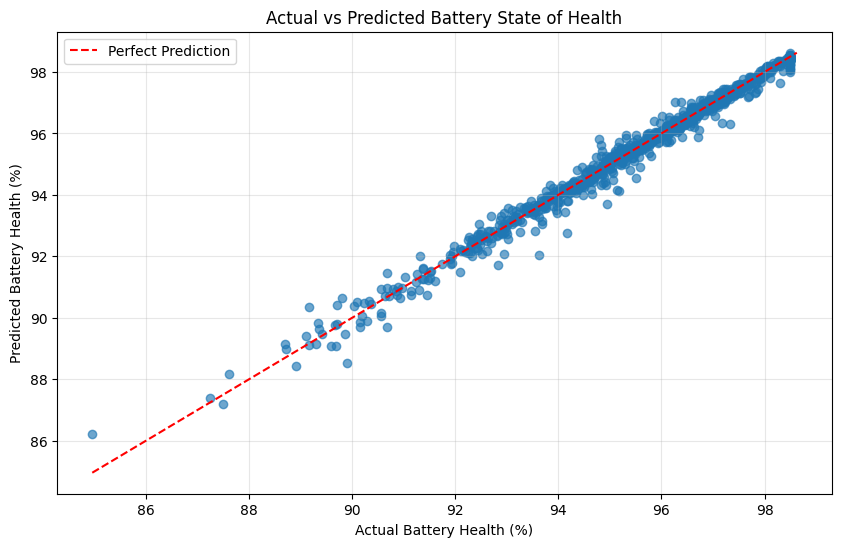

In [40]:
fig = plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred, alpha=0.65)
lims = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]
plt.plot(lims, lims, 'r--', label='Perfect Prediction')
plt.xlabel('Actual Battery Health (%)')
plt.ylabel('Predicted Battery Health (%)')
plt.title('Actual vs Predicted Battery State of Health')
plt.legend()
plt.grid(alpha=0.3)
plt.show()